##EECS 253 Lecture 5: Simple Recurrent Network

Recurrent neural networks (RNNs) model dynamic systems.  (This is not the same as a "recursive" network which is a nested network structure.)  A typical dynamic system has equations of the form:
\begin{equation}
\dot{x} = Ax + Bu \\
y = Cx
\end{equation}
where $x$ is the state, $u$ is the input, and $y$ is the observed output. In discrete time, we have:
\begin{equation}
x(t+1) = Ax(t) + Bu(t) \\
y(t+1) = Cx(t+1)
\end{equation}

There are many uses of dynamic systems.  One is as a filter, in which the goal is to infer $x$ from observations of $y$ (which is usually lower-dimensional).  This is the basis of a Kalman filter.  In a Kalman filter, we assume that we know $A$, $B$, and $C$, that $u$ is noise, and we create an estimate $\hat{x}$ of $x$ at each step. We then create a predicted observation $\hat{y} = C\hat{x}$, and use the error $y-\hat{y}$ to correct our estimate of $\hat{x}$, so that $\hat{x}(t+1) = K(y-\hat{y})$ where $K$ is the "Kalman Gain" and is derived from knowledge of the system noise.

Another use is in system identification, where we take measurements of $y$ and $u$, and use the Laplace transforms to estimate the transfer function $Y(s) = H(s)U(s)$, or $H(s) = U(s)/Y(s)$.  Then we find a ratio of polynomials in $s$ that approximate the transfer function
\begin{equation}
H(s) \approx \frac{b_0 + b_1s + b_2 s^2 + \ldots}{1 + a_1s + a_2s^2 + \ldots}
\end{equation}
which is consistent with the ARMA model
\begin{equation}
y + a_1y' + a_2y'' +\ldots = b_0u + b_1u' + b_2u'' + \ldots
\end{equation}
which can be written as a state-space model of the form
\begin{equation}
y = -a^T<y', y'', ...> + b^T<u, u', u'', ...> \\
y' = y' \\
\ldots\\
\dot{\cal Y} = A{\cal Y} + B{\cal U}
\end{equation}
where the rows beyond the first represent the relationship between the various derivatives.

The point is that we frequently end up with equations that look like
\begin{equation}
\dot{x} = Ax + Bu, y=Cx \\
x(t+1) = Ax(t) + Bu(t), y(t+1) = Cx(t+1)
\end{equation}

So here we are going to use the Keras "SimpleRnn" model to create exactly this kind of structure (in the discrete-time domain).  How does this work?  SimpleRnn implements the following equation:
\begin{equation}
x(t+1) = Ax(t) + Bu(t)
\end{equation}
The input is $u(t), u(t-1), \ldots u(t-N)$ for some "predict_length" $N$.   The output is $x(t+1)$ at a single time. (You could output $x(t)$ at all intermediate times, but that would just be a standard memoryless mapping). The point is that $x(t)$ is not memoryless, but in fact depends on the prior values of $x(t-n)$, and there uses memory of the last $N$ samples, where this memory is stored in the "state" $x$.

How does SimpleRNN do this?  Each "hidden unit" actually has memory of its own past state.  So at time $t$, each hidden unit in the RNN looks at the current input $u(t)$ but also looks at its own prior value $x(t-1)$.  There are weights from both inputs, so that $x(t) = Ax(t-1) + Bu(t-1)$. So this exactly implements the idea of a dynamic system.  It is up to us to read out the output using another "dense" layer to obtain $\hat{y}(t) = Cx(t)$.  We could calculate errors at every time step comparing the true output to the predicted output $y-\hat{y}$, but typically we only do this for the "final" output, or after a finite number of time steps.  Why do that?  Because it forces the network to learn a good update matrix $A$.  If you always have access to the correct output, you might not have to learn to make the iterated predictions $x(t+1) = Ax(t)$.  So we only look at $y(t_{final})$.  

Then we use "backpropagation through time" to figure out $A$ and $B$.   How does that work?  Well, we need an initial $x(0)$ (usually zero, but could be taken from a previous estimate). Then that "forward propagates" through the $A$ matrix a few times to get $x(t+N) = A^Nx(0)$.  At each step we add in $Bu(t)$.  So we can backpropagate the final error $y(t+N)-\hat{y}(t+N)$ through the $A$ matrix (which is the same at each time step) and the $B$ matrix (back to different values of $u(t)$ at each time step, subject to the constraint that there is only one $A$ and one $B$ matrix.  

Note that this is different from the Kalman filter formulation, and closer to system identification, because we learn the $A$ and $B$ matrices, rather than assuming we know them in advance.  At the same time we learn the values for the hidden state $x$. We will have to assume we know the dimension of $x$, but we can try multiple different sizes for that to see what works.




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

import seaborn as sns
import tensorflow as tf

#for your homework
np.random.seed(10327798)
tf.random.set_seed(10327798)

In [ ]:
#use the EEG dataset that we used for Lecture 1.
# in this case, we use all 14 channels so that this is multivariate timeseries
# the input u(t) is a vector at each point in time <u_1(t), u_2(t), .... u_14(t)>
from sklearn.datasets import fetch_openml
eeg = fetch_openml(data_id=1471,as_frame= True )
#this timeseries dataset does not actually include time.  So we will synthesize timestamps
increment = 117 / len (eeg[ 'data' ])
index = np.linspace(
start= 0 ,
stop=increment* len (eeg[ 'data' ]),
num= len (eeg[ 'data' ])
)
ts_index = pd.to_datetime(index, unit= 's' ,origin = '2022-1-3 15:30:00')  #convert to seconds

In [ ]:
#make a dataframe out of this. Series usually only have a single value;  we need a dataframe for all 14.
#   remember that dataframes look like spreadsheets.
eeg_df = pd.DataFrame(data=eeg[ 'data' ].values, index=ts_index)
eeg_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
2022-01-03 15:30:00.000000000,4329.23,4009.23,4289.23,4148.21,4350.26,4586.15,4096.92,4641.03,4222.05,4238.46,4211.28,4280.51,4635.90,4393.85
2022-01-03 15:30:00.007810831,4324.62,4004.62,4293.85,4148.72,4342.05,4586.67,4097.44,4638.97,4210.77,4226.67,4207.69,4279.49,4632.82,4384.10
2022-01-03 15:30:00.015621901,4327.69,4006.67,4295.38,4156.41,4336.92,4583.59,4096.92,4630.26,4207.69,4222.05,4206.67,4282.05,4628.72,4389.23
2022-01-03 15:30:00.023432732,4328.72,4011.79,4296.41,4155.90,4343.59,4582.56,4097.44,4630.77,4217.44,4235.38,4210.77,4287.69,4632.31,4396.41
2022-01-03 15:30:00.031243801,4326.15,4011.79,4292.31,4151.28,4347.69,4586.67,4095.90,4627.69,4210.77,4244.10,4212.82,4288.21,4632.82,4398.46
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-01-03 15:31:56.968756199,4281.03,3990.26,4245.64,4116.92,4333.85,4614.36,4074.87,4625.64,4203.08,4221.54,4171.28,4269.23,4593.33,4340.51
2022-01-03 15:31:56.976567268,4276.92,3991.79,4245.13,4110.77,4332.82,4615.38,4073.33,4621.54,4194.36,4217.44,4162.56,4259.49,4590.26,4333.33
2022-01-03 15:31:56.984378099,4277.44,3990.77,4246.67,4113.85,4333.33,4615.38,4072.82,4623.59,4193.33,4212.82,4160.51,4257.95,4591.79,4339.49
2022-01-03 15:31:56.992189169,4284.62,3991.79,4251.28,4122.05,4334.36,4616.41,4080.51,4628.72,4200.00,4220.00,4165.64,4267.18,4596.41,4350.77


In [ ]:
# there is an artifact at 1:10, so select a slice of time before
slicing = (eeg_df.index >= '2022-1-3 15:30:08' ) & (eeg_df.index <= '2022-1-3 15:31:10.000000000' )
#the result is still a pandas series, with timestamp, value pairs.

/tmp/ipython-input-267977326.py:4: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(eeg_df.loc[slicing,1:13])   #there are 14 columns total


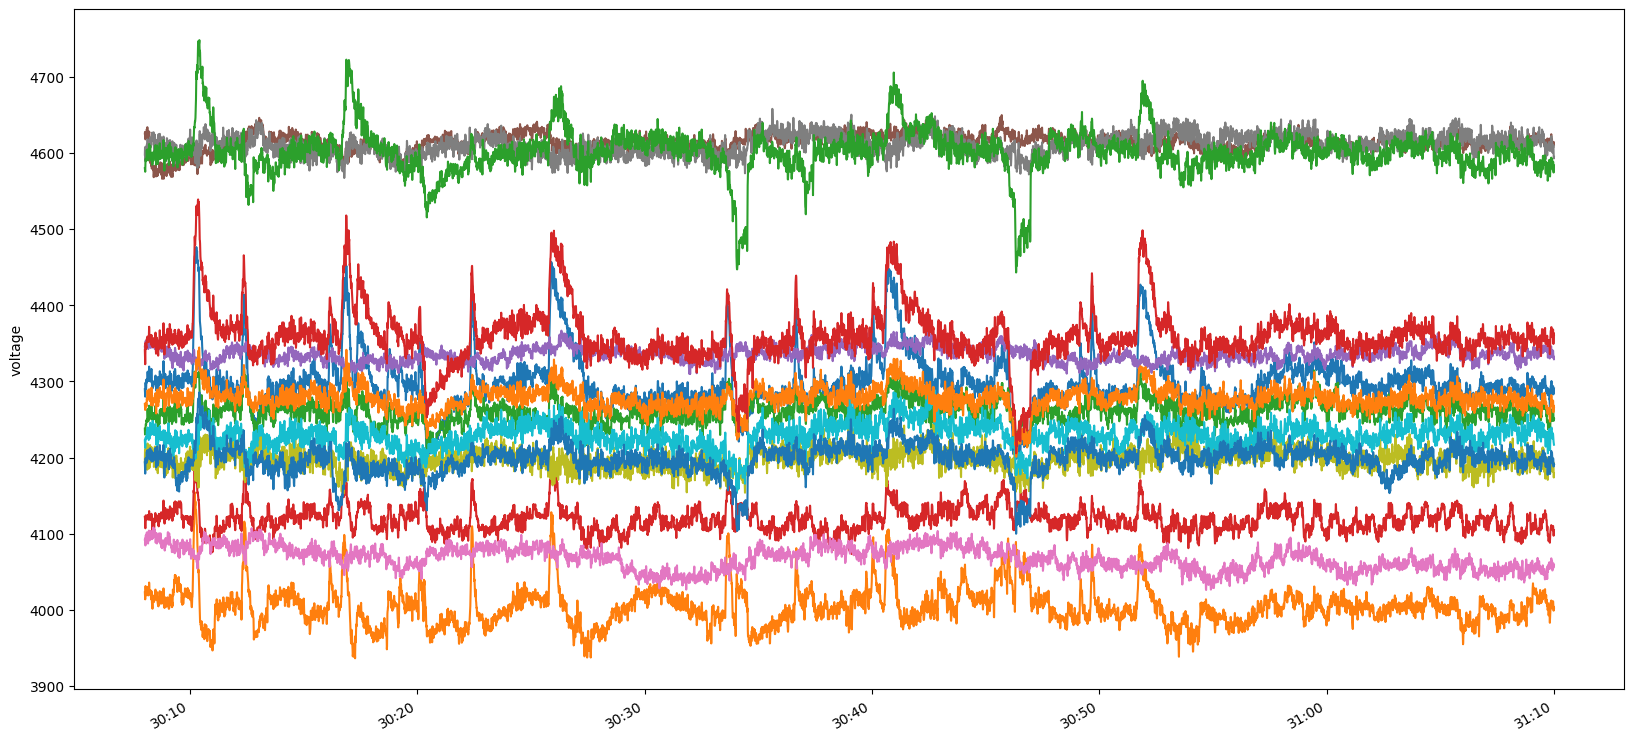

In [ ]:
#same time formatter we used before.  look at the raw data
date_formatter = DateFormatter( "%M:%S" )  #just show minutes:seconds
ax = eeg_df.loc[slicing,0].plot(figsize=( 20 , 10 ))  #will use the same axes for all; set dateformatter based on first
plt.plot(eeg_df.loc[slicing,1:13])   #there are 14 columns total
ax.xaxis.set_major_formatter(date_formatter)
plt.ylabel( 'voltage' );



In [ ]:
#scale the range.  scale separately for each of the 14 data channels
from sklearn.preprocessing import StandardScaler   #use standard normal (mean 0, std 1) rather than min/max scaler here
scaler = StandardScaler()
scaler.fit(eeg_df[slicing])  #use only the sliced data for the fit
eeg_scaled = scaler.transform(eeg_df[slicing])  #from here on we use only the sliced data
eeg_scaled_df= pd.DataFrame(data=eeg_scaled, index=ts_index[slicing])
eeg_scaled_df[0:10]  #take a look

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
2022-01-03 15:30:08.006208658,-0.266739,0.735518,-1.557530,0.192408,1.088466,0.964741,1.630955,-0.991542,-0.308114,-0.464933,-0.228375,-0.513778,-0.716078,-0.520897
2022-01-03 15:30:08.014019728,-0.425490,0.513663,-2.080956,0.030059,0.707039,1.143768,1.733216,-0.254797,1.023512,-0.821951,-0.625475,-0.757114,-0.819031,-0.848184
2022-01-03 15:30:08.021830559,-0.540894,0.372447,-1.941421,-0.652950,0.870660,0.964741,1.698687,-0.293374,0.357317,-1.081486,-0.995758,-1.035697,-0.870508,-1.033184
2022-01-03 15:30:08.029641390,-0.266739,0.715063,-1.836600,-0.750613,1.361521,0.293170,1.120311,-1.496068,-0.974309,-0.789035,-0.546055,-0.861498,-0.613125,-0.620470
2022-01-03 15:30:08.037452459,-0.021295,1.058073,-1.522816,-0.099948,1.741885,0.427659,1.221909,-1.689709,-0.425768,-0.237682,0.035670,-0.410072,-0.304600,-0.250747
2022-01-03 15:30:08.045263290,-0.107988,0.876734,-1.138925,0.322414,1.905505,1.099229,2.005471,-0.952965,0.240427,-0.237682,-0.096353,-0.444640,-0.304600,-0.407179
2022-01-03 15:30:08.053074360,-0.266739,0.573847,-1.138925,0.062402,1.633513,1.099229,2.005471,-1.069452,-0.308114,-0.367449,-0.255193,-0.479209,-0.390505,-0.464038
2022-01-03 15:30:08.060885191,-0.252103,0.654879,-1.208352,-0.067605,1.197900,0.875664,1.460298,-1.457491,-0.269151,-0.269965,-0.122654,-0.410072,-0.356076,-0.364465
2022-01-03 15:30:08.068696260,-0.064642,0.796095,-0.929283,0.160065,1.142652,0.516736,1.494827,-0.991542,0.436008,-0.204765,-0.228375,-0.618161,-0.339029,-0.407179
2022-01-03 15:30:08.076507092,0.094109,0.856279,-0.824461,0.257728,1.524079,0.516736,1.834814,-0.564926,0.279391,-0.237682,-0.281494,-0.722545,-0.339029,-0.449893


##How SimpleRNN works
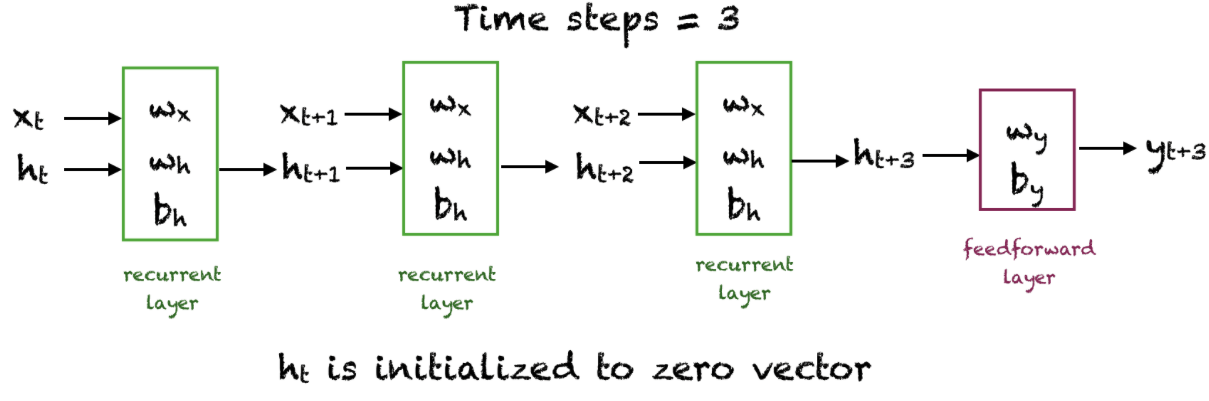

(figure and code from https://machinelearningmastery.com/understanding-simple-recurrent-neural-networks-in-keras/)

The SimpleRNN has a sequence of inputs $x_t$ (shown here as a total of 3 inputs in sequence), and a state $h_t$ which is updated every time an input arrives.  The output of the SimpleRNN layer is the value of the final state $h_{t+3}$.  In the figure above, this output is fed to another Dense memoryless network layer (in red) that produces $y_{t+3} = w_y h_{t+3} + b_y$.  In other words, the SimpleRNN unit takes a sequence of vector inputs $x_t$ and produces a single vector output $h_{t+N}$, where $x_t$ and $h_t$ are generally vectors.  The dimension of $h$ is specified as the "hidden units" or "number of outputs" of the SimpleRNN layer.

The initial state $h_0=0$, but you can set it to be something else if you like.    For example, you can set the flag "stateful=True" when you create the layer in which case the initial $h_t$ will be the last value ($h_{t+2}$) from the last time the layer was called (be careful if you do this when batch_size is not 1).  

SimpleRNN calculates a sequence of values of $h_t$ before it outputs the final value.  If you want to see this sequence of intermediate values ($h_1, h_2$, etc.) then you can set "return_sequences" to be True, which will output $h_t, h_{t+1}, \ldots$ in addition to just the final $h_{t+3}$.

(Note: there is another parameter "return_state" which does nothing because SimpleRNN already returns its state.  This is not true for LSTM nodes, which have an additional internal state that you can access.)

In [ ]:

#https://machinelearningmastery.com/understanding-simple-recurrent-neural-networks-in-keras/

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape
from tensorflow.keras.layers import SimpleRNN

def create_RNN(hidden_units, dense_units, input_shape):
    model = Sequential()
    model.add(SimpleRNN(hidden_units, input_shape=input_shape,
                        activation='linear'))
    model.add(Dense(units=dense_units, activation='linear'))
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model
#create a net with 2 simpleRNN hidden units, 1 linear output unit, and predict_length = 3
demo_model = create_RNN(2, 1, (3,1))
#find the weights of the model (we have not trained it on anything, so these are just random initial values)
wx = demo_model.get_weights()[0]#weight
wh = demo_model.get_weights()[1]#weight [hidden layer]
bh = demo_model.get_weights()[2]#bias [[hidden layer]]
wy = demo_model.get_weights()[3]#weight
by = demo_model.get_weights()[4]#bias

print('wx = ', wx, ' wh = ', wh, ' bh = ', bh, ' wy =', wy, 'by = ', by)

# Reshape the input to the required batch_size x predict_length x features
x = np.array([1, 2, 3])  #random values, 0x3 vector
x_input = np.reshape(x,(1, 3, 1))  #turn into a 1x3x1 array (tensor) ## check here
y_pred_model = demo_model.predict(x_input)  #network output


m = 2
h0 = np.zeros(m)  #initial state
h1 = np.dot(x[0], wx) + h0 + bh   #state update for first state
h2 = np.dot(x[1], wx) + np.dot(h1,wh) + bh  #general state update:  wh*h + wx*x + b  (x(t+1)=Ax(t)+Bu(t)+D(t))
h3 = np.dot(x[2], wx) + np.dot(h2,wh) + bh
o3 = np.dot(h3, wy) + by  #top layer output (y(t) = Cx(t))

print('h1 = ', h1,'h2 = ', h2,'h3 = ', h3)  #state is two-dimensional (hidden_units=2)

print("Prediction from network ", y_pred_model)
print("Prediction from our computation ", o3)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


wx =  [[ 0.68368447 -1.2037646 ]]  wh =  [[ 0.6459514   0.76337874]
 [-0.76337874  0.6459512 ]]  bh =  [0. 0.]  wy = [[ 0.69656765]
 [-0.08129585]] by =  [0.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step
h1 =  [[ 0.68368447 -1.20376456]] h2 =  [[ 2.72792414 -2.6631921 ]] h3 =  [[ 5.84618403 -3.24914655]]
Prediction from network  [[4.3364043]]
Prediction from our computation  [[4.33640482]]


#TimeSeriesGenerator for multivariate data passed to an RNN
this is a bit special.  The reason is that the RNN is trained on lagged data values $u(t) \ldots u(t-N)$.  But this is not the same as the "predict_length" variable we used in the past.  predict_length = 5 means that we use the last 5 data samples as 5 separate inputs to the network.  For a univariate timeseries, this means the network would have 1x5 = 5 inputs, or for a multivariate network 14x5 = 70 inputs, each with its own weight.

But for an RNN, the situation is different.  We predict over several steps, but the weights for each step are the same.  So we need to make sure that we present the data to the network in the correct format.

Here is the relationship between predict_length and batch_size.  predict_length = 5 says we look back 5 time steps to predict a single output.  batch_size = 5 says we predict 5 outputs from 5 time steps.  In other words, this is 5 separate predictions.  Predict_length = 2 and batch_size = 5 means that at each of 5 time steps we look 2 steps back to make 5 separate predictions (one for each time step).  In the case of an RNN, we look back 5 time steps, but we predict only the final output, so batch_size=1, and predict_length =5.

How does the network know not to use 5 past values simultaneously but rather to put them into each time step of the RNN?  Well, that's an assumption that SimpleRNN makes.  It assumes  that you only use one time step at a time.  If you want more, you will have to include those manually.  For SimpleRNN, predict_length means how many time steps back you start the dynamic system.  

So here, for the TimeSeriesGenerator we use predict_length = 16 (slightly larger than the dimensionality of the timeseries.  This is because it usually takes at least that many time steps to converge).  We use batch_size=1 because we only have a single target output $y$ at the end of each complete 14-step timeseries.





In [ ]:
#predict 16 lagged time-steps where we have 14 variables (electrodes) at each timestep.
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = 16
generator14 = TimeseriesGenerator(eeg_scaled_df.values, eeg_scaled_df.values, length =predict_length , batch_size=1)  #use at least 14 points because 14 dimensions
#NOTE1:  you have to use df.values or you get weird indexing errors
#NOTE2:  batch_size=1 because we only use the current input data.  predict_length=14 because we need 14 input/output pairs to train the RNN
generator14[0]

(array([[[-0.26673919,  0.73551812, -1.5575299 ,  0.19240794,
           1.08846593,  0.96474065,  1.63095483, -0.99154169,
          -0.30811384, -0.46493282, -0.22837549, -0.51377758,
          -0.71607808, -0.52089734],
         [-0.42549   ,  0.5136634 , -2.08095593,  0.03005864,
           0.70703924,  1.14376796,  1.73321638, -0.25479724,
           1.02351222, -0.82195121, -0.62547509, -0.75711392,
          -0.81903123, -0.84818406],
         [-0.54089395,  0.37244736, -1.94142103, -0.65294992,
           0.87065961,  0.96474065,  1.6986865 , -0.29337421,
           0.3573172 , -1.08148585, -0.99575757, -1.03569674,
          -0.87050781, -1.03318427],
         [-0.26673919,  0.71506343, -1.83659969, -0.75061317,
           1.3615207 ,  0.29316991,  1.12031112, -1.49606793,
          -0.97430887, -0.78903462, -0.54605517, -0.86149775,
          -0.61312493, -0.62047017],
         [-0.02129468,  1.05807286, -1.52281634, -0.09994763,
           1.74188492,  0.42765872,  1.2219086

Note above that there are 16 samples of each of the 14 variables, but only a single output of the 14 variables which is the target.

When we build the SimpleRNN network model, we use predict_length as the input, but remember that for SimpleRNN this means the number of iterated samples, each of predict_length=1, that are actually used as input to the network.

We also use n_features as the final output from the network because we are trying to predict the next 14 channels of EEG.

The shape of the input generated by generator is (batch_size, predict_length, n_features).  batch_size is implicit, so you do not generally need to specify it when you construct your network model.  n_features is the dimensionality of the input.  and predict_length is how many timesteps in the past you look at.  In prior models, we used a flatten() layer to look at all the past timesteps at the same time.  Here we are going to look at each past timestep one at a time, with SimpleRNN working on each one to get to the next timestep.

You can calculate the total number of parameters.  There are 14 inputs, 4 hidden units, and a bias unit for each of the hidden units.  There are also 16 weights that map each of the hidden units $x(t)$ onto those same hidden units at $x(t+1)$.  So we have 14x4 + 4 + 4x4 = 76 weights in the SimpleRNN layer.  Then for each of the 4 units in the RNN layer, we have 14 outputs plus 14 bias terms, which is 4x14 + 14 = 70.

Note that the number of parameters does NOT depend on predict_length (it never does).  For SimpleRNN, that is because the same weight matrices A,B, and C are used at each timestep.  In fact, you can specify "None" for predict length in the input shape and SimpleRNN will just run each sample to the end.

In [ ]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, Flatten
from tensorflow.keras.layers import SimpleRNN
n_features = 14
n_hidden = 4
model = Sequential()
#input_shape is actually (batch_size, predict_length, n_features), but batch_size is implicit from the generator
model.add(SimpleRNN(n_hidden, activation='linear', input_shape=(predict_length, n_features)))  #feel free to use 'sigmoid' or 'relu' units
model.add(Dense(n_features))
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 4)              │            76 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │            70 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 146 (584.00 B)

 Trainable params: 146 (584.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(generator14,epochs=3)

Epoch 1/3


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7921/7921 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - loss: 1.5929
Epoch 2/3
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 0.2668
Epoch 3/3
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 0.2326


<Axes: >

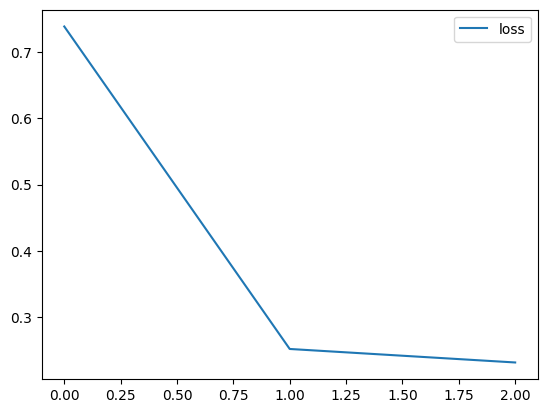

In [ ]:
losses = pd.DataFrame(model.history.history)
losses.plot()

Let's look at the weights. The first layer is the weights from the 14 inputs to the 4 hidden units.  This is the $B$ matrix. The next is the weights from the 4 hidden units back to themselves at the next time.  This is the $A$ matrix. So we have $x(t+1) = Ax(t) + Bu(t)$  The next is the weights from the 4 hidden units to the 14 outputs, this is the $C$ matrix, giving $y(t+1) = Cx(t+1)$.  And you have the 4 biases to the hidden units and 14 biases to the outputs.  

In [ ]:
model.weights

[<Variable path=sequential_1/simple_rnn_1/simple_rnn_cell/kernel, shape=(14, 4), dtype=float32, value=[[-0.0162563   0.29890594  0.37897155 -0.0905465 ]
  [-0.47040153 -0.22266953  0.5539016  -0.41841364]
  [ 0.14249483  0.04140745  0.30746892 -0.38993293]
  [-0.30865493 -0.16478243  0.45592174 -0.3823417 ]
  [ 0.21366161 -0.5728877   0.38487408 -0.13518843]
  [ 0.32466662 -0.44714606  0.07424639 -0.26812896]
  [ 0.46080023 -0.58781856  0.59694684  0.465565  ]
  [ 0.43708175  0.04798285 -0.2627668  -0.17739989]
  [ 0.66255456 -0.12665421 -0.06553644 -0.01437904]
  [ 0.41404045 -0.15296637  0.08892071  0.07433013]
  [ 0.5642564   0.23615591  0.03953665 -0.02850517]
  [ 0.21021007  0.10868487  0.09195722 -0.00982436]
  [ 0.4289097   0.41199133  0.1739399   0.06371754]
  [ 0.60266316  0.24242966  0.83901346 -0.13107452]]>,
 <Variable path=sequential_1/simple_rnn_1/simple_rnn_cell/recurrent_kernel, shape=(4, 4), dtype=float32, value=[[-0.9004068   0.05705337 -0.16985324  0.05242654]
  [ 0.

In [ ]:
#get the model predictions for all timepoints
predicted_outputs = model.predict(generator14)  #this is a 14 element vector for each time point
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
predict_df = pd.DataFrame(data=predicted_outputs, index=eeg_scaled_df.index[predict_length:])  #14 columns plus the timestamp column
orig_df = pd.DataFrame(data=eeg_scaled_df[predict_length:], index=eeg_scaled_df.index[predict_length:len(eeg_scaled_df)])


7921/7921 ━━━━━━━━━━━━━━━━━━━━ 11s 1ms/step


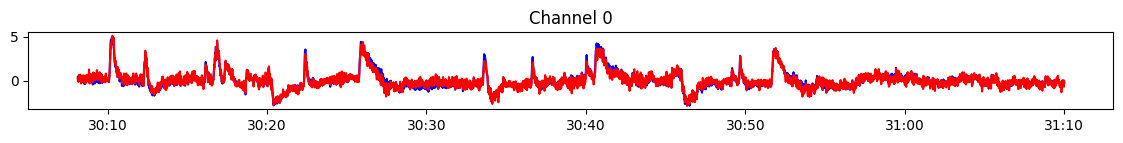

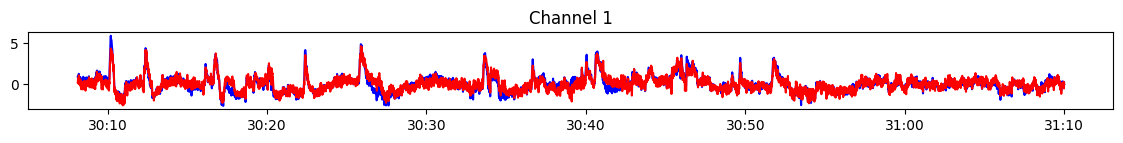

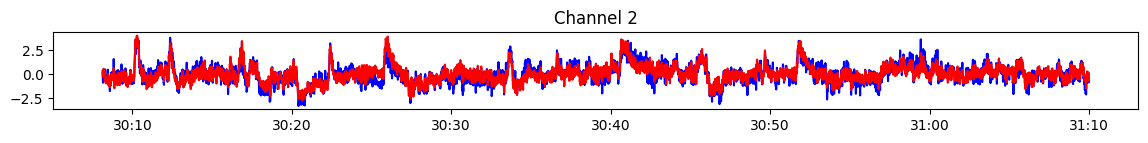

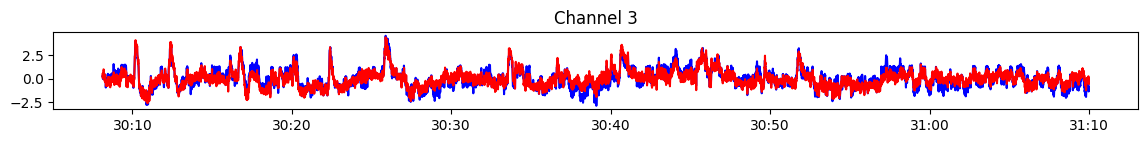

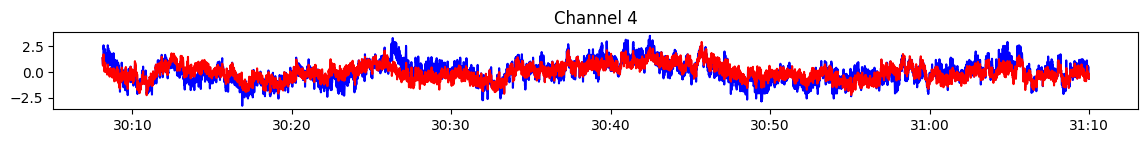

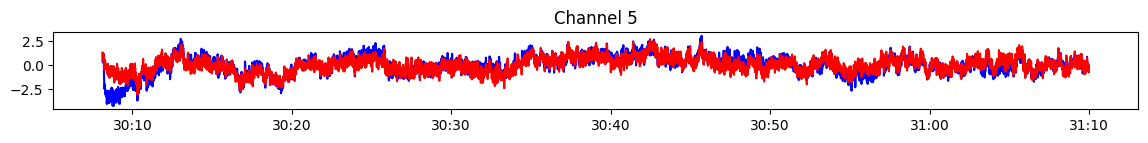

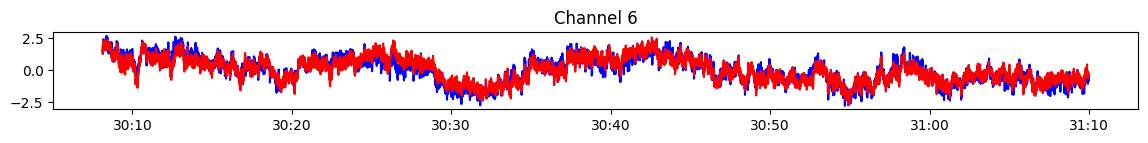

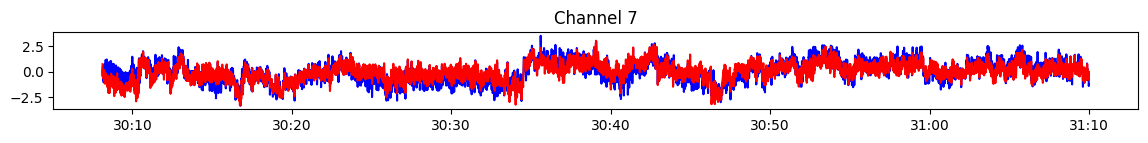

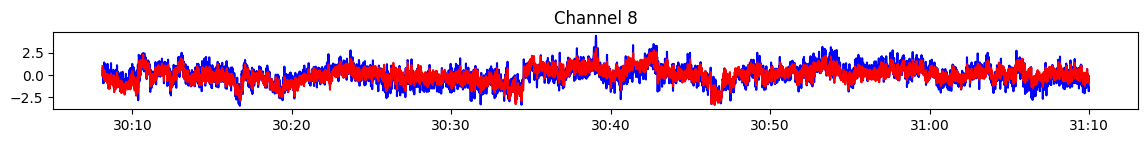

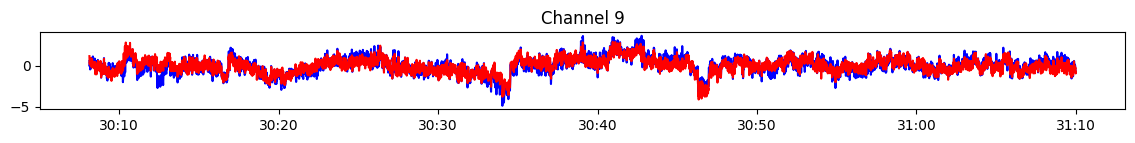

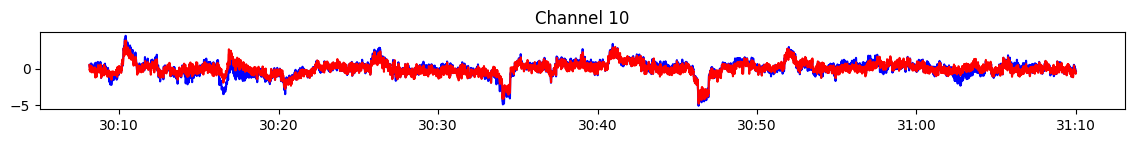

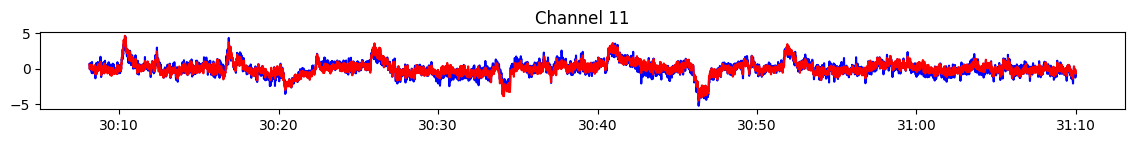

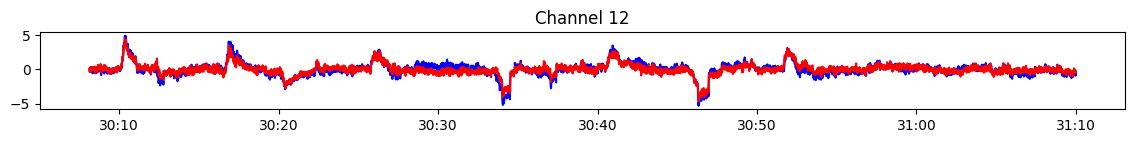

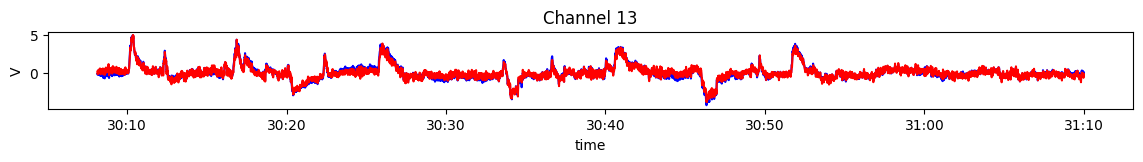

In [ ]:
#show the model predictions.  each output prediction is formed using the previous 16 input datapoints
for n in range(n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'b')  #compare one column at a time
  plt.plot(predict_df[n],'r')
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');


If you want to play with this, look at using linear, sigmoid, or relu activations in the network, and experiment with differing numbers of hidden units.

#Unsupervised Learning of the hidden states is implicit in SimpleRNN
We did not specify what the "hidden" states should be.  The network has learned weight matrices A, B, and C such that the dynamic model
\begin{equation}
x(t+1) = Ax(t) + Bu(t)\\
y(t+1) = C x(t+1)
\end{equation}
but in order to do so, it chooses these matrices so that x(t) is somehow the best representation (or at least an adequate representation) of a 4 dimensional state driving a 4 dimensional observation.  So the state itself may be interesting, and may capture some important features of the input.  This is one example of how a supervised learning algorithm can extract hidden patterns from data, thus performing unsupervised learning.

In [ ]:
#calculate the vvalues of the hidden states
hidden_states = np.dot(eeg_scaled_df.values,model.weights[0])
nTimes,nStates = np.shape(hidden_states)

/tmp/ipython-input-1759798378.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  hidden_states = np.dot(eeg_scaled_df.values,model.weights[0])


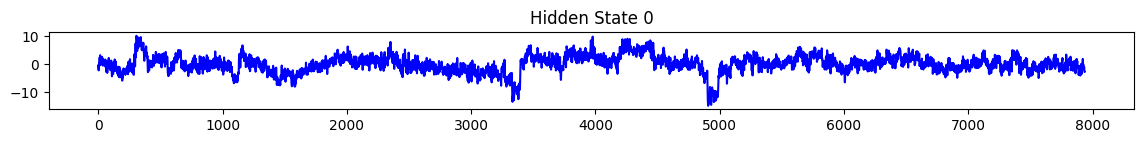

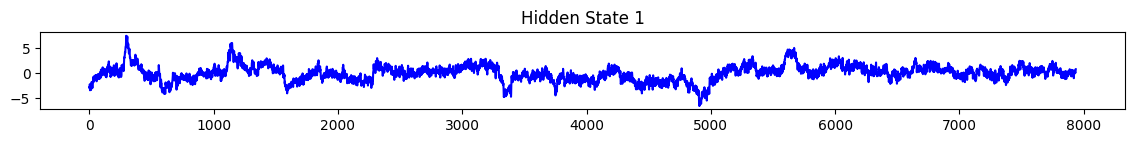

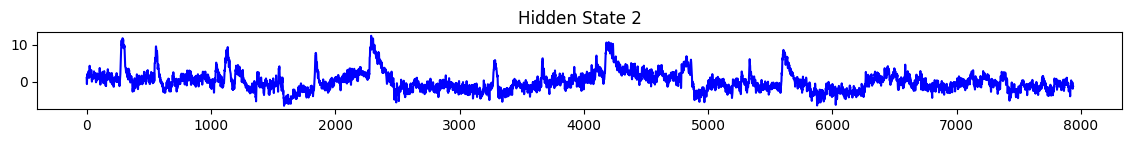

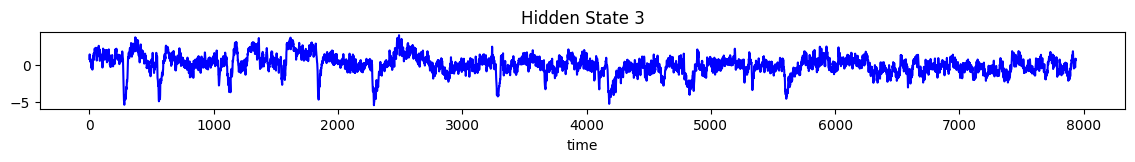

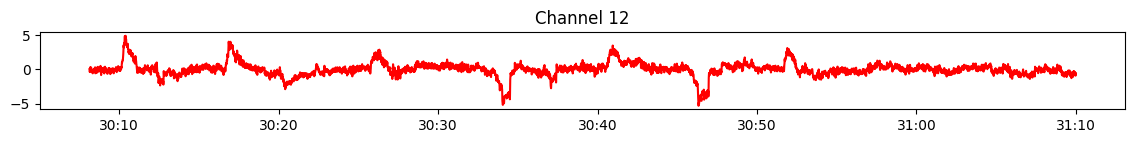

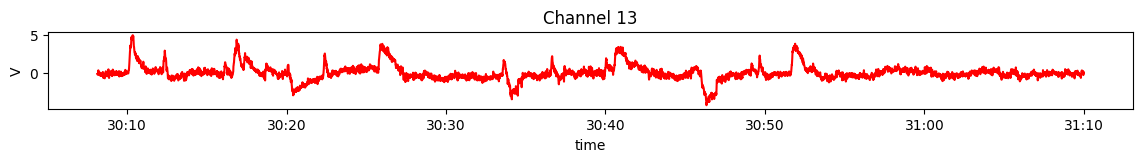

In [ ]:
#plot the time values of the hidden states
for n in range(0,nStates):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  plt.plot(hidden_states[:,n],'b')  #compare one column at a time
  plt.title('Hidden State {}'.format(n))
plt.xlabel('time');
#show some of the original data for comparison
for n in range(12,n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'r')  #compare one column at a time
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');


#Overfitting and Dropout
SimpleRNN's do not have as much of a problem with overfitting as you might think, mostly because they use a form of weight sharing.  In other words, the A and B matrices are *constrained* to be the same at each time point.  This means that they have to fit all the time points together.  However, if there are a lot of hidden states, then there is a risk that the network will fit the training data really well without really figuring out anything meaningful about the structure of the timeseries.  

One way to avoid this is to use dropout.  In dropout, some of the weights are set to zero randomly during each training batch.  This happens only during training; all weights are revived before making predictions.  The network then never quite knows which weights it has available for use during training, which means it has to distribute what it knows over a small number of weights.  One way to think of this is that if you know that 25% of the employees of your company will be sick on any given day, you need to make sure they can all do each others' jobs, and the number of jobs has to be less than the number of employees.  This is a constraint that tends to reduce overfitting.

For recurrent nodes such as SimpleRNN, the dropout for the matrix A and B has to be the same for each input x(t-n) in the predict_length.  So there is an internal parameter "recurrent_dropout" that keeps the dropout the same for each batch.

For a dense layer, the dropout can be different for each example, and this is implemented by a dropout layer that instead of setting the weights randomly to zero, sets the inputs randomly to zero (which does the same thing since the inputs multiply the weights).  Remember, this only happens during the training phase.  All the dead weights come back to life when you run the network to make predictions.

In [ ]:
#same network with dropout, and more hidden units.
from tensorflow.keras.layers import Dropout

n_features = 14
n_hidden = 8
model = Sequential()
model.add(SimpleRNN(n_hidden, activation='linear', recurrent_dropout = 0.5, input_shape=(predict_length, n_features)))  #feel free to use 'sigmoid' or 'relu' units
model.add(Dropout(0.5))
model.add(Dense(n_features))
model.compile(optimizer='adam', loss='mse')
model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_3 (SimpleRNN)        │ (None, 8)              │           184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 14)             │           126 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310 (1.21 KB)

 Trainable params: 310 (1.21 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 22s 2ms/step - loss: 1971869.3750
Epoch 2/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 2430.0391
Epoch 3/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 46.1981
Epoch 4/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 1.9525
Epoch 5/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 0.7285
Epoch 6/6
7921/7921 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 0.5088


<Axes: >

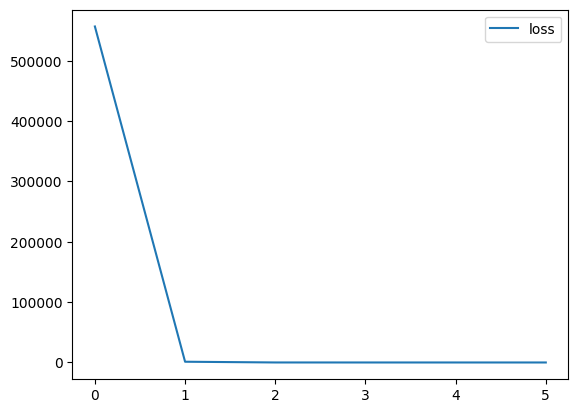

In [ ]:
#tend to need more epochs with dropout, because there is more variability during training.

model.fit(generator14,epochs=6)
losses = pd.DataFrame(model.history.history)
losses.plot()


7921/7921 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


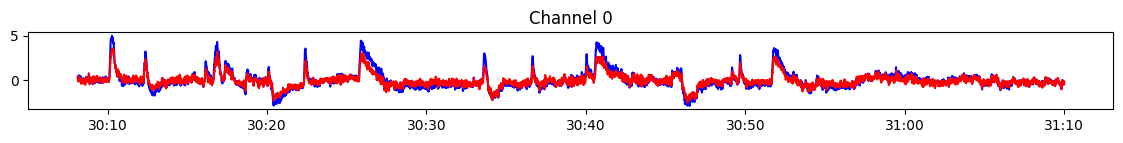

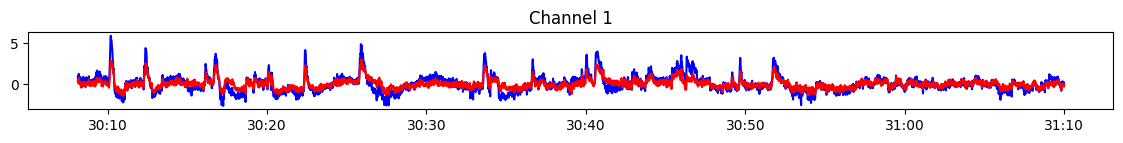

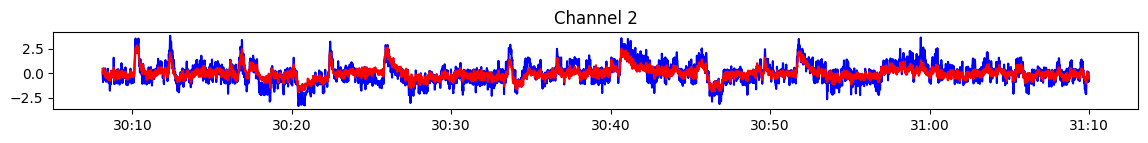

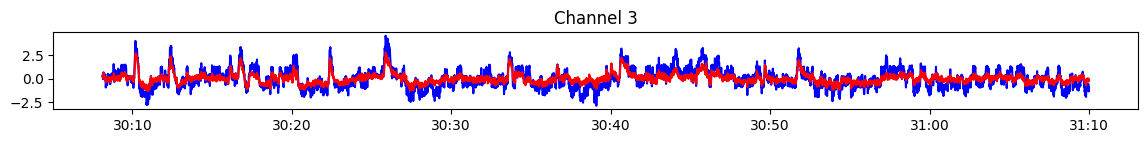

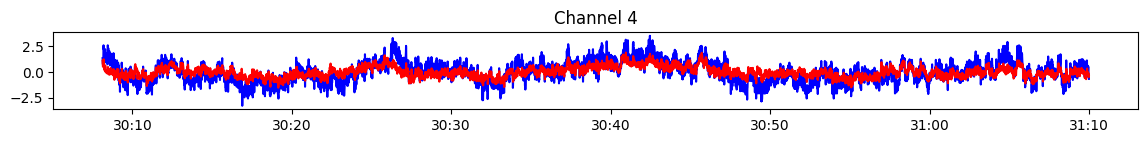

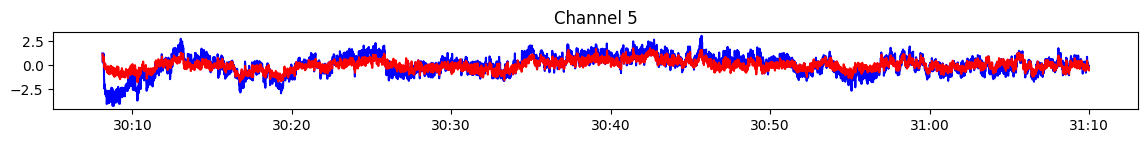

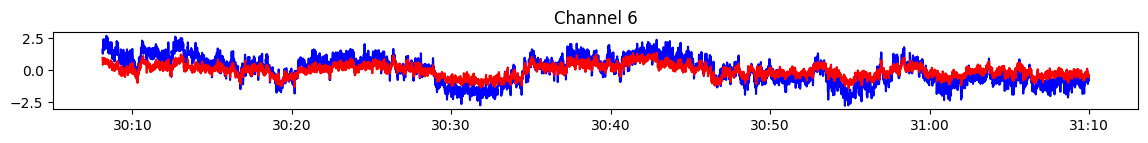

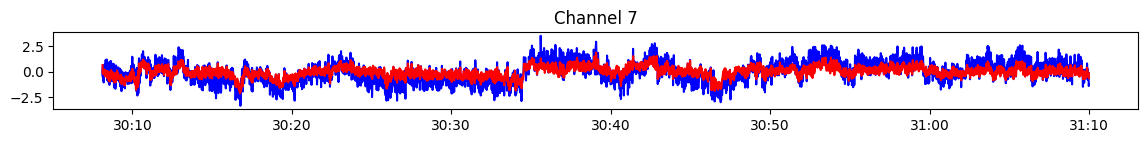

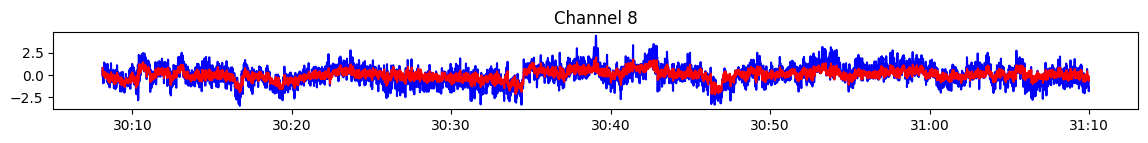

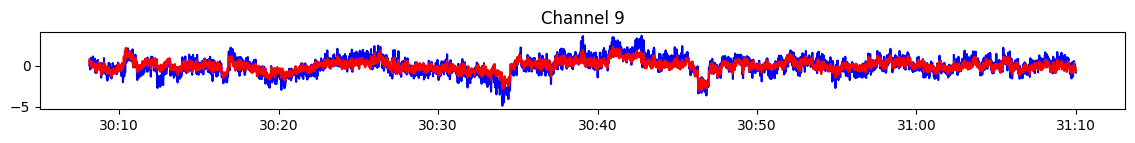

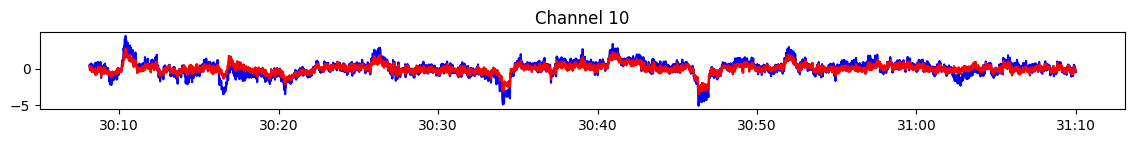

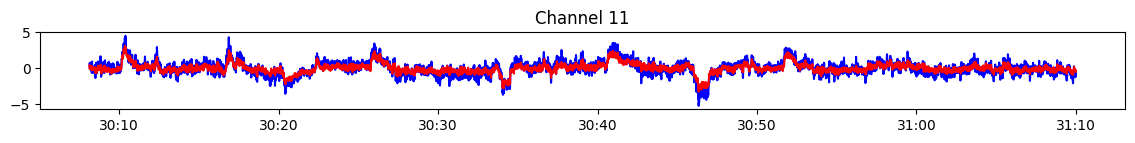

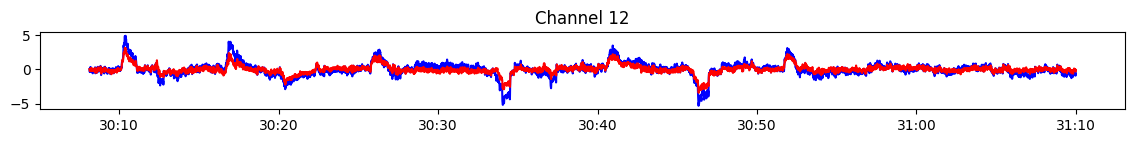

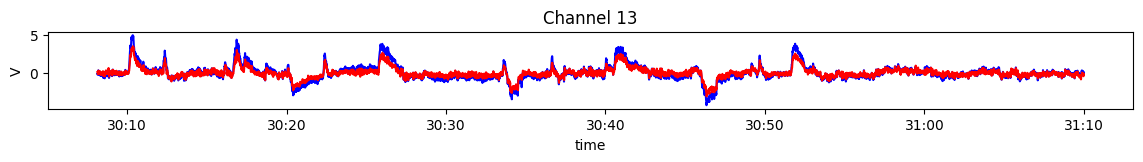

In [ ]:
#get the model predictions for all timepoints
predicted_outputs = model.predict(generator14)  #this is a 14 element vector for each time point
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
predict_df = pd.DataFrame(data=predicted_outputs, index=eeg_scaled_df.index[predict_length:])  #14 columns plus the timestamp column
orig_df = pd.DataFrame(data=eeg_scaled_df[predict_length:], index=eeg_scaled_df.index[predict_length:len(eeg_scaled_df)])
for n in range(n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'b')  #compare one column at a time
  plt.plot(predict_df[n],'r')
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');